# 02 · Spatial graphs, homophily and patient splits

> Part of the spatial-niche-gbm walk-through. The project is a **benchmark**: it tests whether spatial graph neural networks improve supervised niche prediction in glioblastoma Visium data over matched graph-free models (they do not). See `docs/00_overview_and_roadmap.md`. Notebooks read `data/` (see `docs/WORKFLOW.md`, step A) and the tracked `results/`; none of them trains a model.

How a Visium section becomes a graph, a caveat about the atlas coordinates, whether the labels are
spatially clustered (homophily), and the three ways patients are split.

In [1]:
import json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

REPO = Path("..").resolve()          # run from notebooks/
PRE = REPO / "data" / "preprocessed"
RES = REPO / "results"
NICHES = ["immune_cold", "immune_hot", "normal", "necrotic"]
COLORS = {"immune_cold": "#D55E00", "immune_hot": "#0072B2", "normal": "#009E73",
          "necrotic": "#CC79A7", "exclude": "#DDDDDD"}
pd.set_option("display.precision", 3)
import torch
from spatial_niche_gbm.data.graph import build_knn_graph

## 1. k-nearest-neighbour graphs

Each spot is joined to its 6 nearest spots. The edges are symmetrised, so some spots end up with more than
6 neighbours. Gaussian edge weights are stored, but neither GraphSAGE nor GAT uses them.

In [2]:
coords = np.load(PRE / "SNU16A_coords.npy")
ei, ea = build_knn_graph(coords, k=6)
print(f"SNU16A: {len(coords):,} spots, {ei.shape[1]:,} directed edges, mean degree {ei.shape[1] / len(coords):.2f}")

SNU16A: 4,712 spots, 32,538 directed edges, mean degree 6.91


## 2. The array-index caveat

The atlas gives positions as Visium **array indices**, where the column index is doubled. On that grid, two
of the six true neighbours tie with second-ring spots, so some 6-NN edges skip a ring. The cell below
compares every published graph with an exact-hexagonal graph (column × ½, row × √3/2) built by
`scripts/23a_build_hex_graphs.py`.

In [3]:
# on true hexagonal coordinates, adjacent spots are exactly 1 unit apart
orig = torch.load(PRE / "graphs.pt", weights_only=False)
n_all = n_far = 0
for g in orig:
    xy = np.load(PRE / f"{g.section}_coords.npy") * np.array([0.5, np.sqrt(3) / 2])
    e = g.edge_index.numpy(); d = np.linalg.norm(xy[e[0]] - xy[e[1]], axis=1)
    n_all += len(d); n_far += int((d > 1.01).sum())
print(f"edges in the published graphs that join non-adjacent (second-ring) spots: {n_far / n_all:.1%}")

edges in the published graphs that join non-adjacent (second-ring) spots: 24.4%


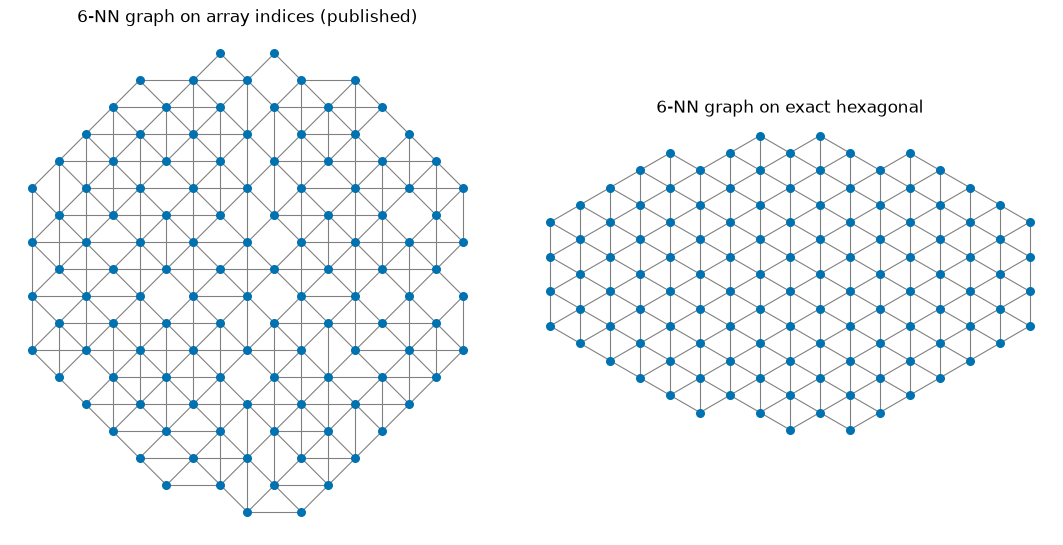

In [4]:
hx = coords * np.array([0.5, np.sqrt(3) / 2])
ei_h, _ = build_knn_graph(hx, k=6)
sub = np.argsort(np.linalg.norm(coords - coords.mean(0), axis=1))[:120]; S = set(sub.tolist())
fig, axes = plt.subplots(1, 2, figsize=(11, 5.5))
for ax, xy, e, title in [(axes[0], coords, ei, "array indices (published)"), (axes[1], hx, ei_h, "exact hexagonal")]:
    for u, v in e.T.tolist():
        if u in S and v in S and u < v:
            ax.plot(xy[[u, v], 1], -xy[[u, v], 0], color="grey", lw=0.8, zorder=1)
    ax.scatter(xy[sub, 1], -xy[sub, 0], s=30, c="#0072B2", zorder=2)
    ax.set_title(f"6-NN graph on {title}"); ax.set_aspect("equal"); ax.axis("off")
plt.tight_layout(); plt.show()

About a quarter of the published edges join second-ring spots. The manuscript discloses this, and the
final GraphSAGE and GAT LOPO runs were repeated on exact-hex graphs (78 runs). Exact geometry did not help
either model (notebook 06, section 4).

## 3. Are the labels spatially clustered?

Graph neural networks struggle when neighbours carry *different* labels (heterophily). If that were the
case here, it would explain a null result trivially.

In [5]:
h = json.load(open(RES / "revision" / "label_homophily.json"))
print(f"overall edge homophily: {h['overall_edge_homophily']:.2f}")
pd.DataFrame(h["per_class"]).T[["n_spots", "homophily", "chance"]]

overall edge homophily: 0.80


,n_spots,homophily,chance
immune_cold,32290.0,0.816,0.672
immune_hot,6614.0,0.665,0.432
normal,21776.0,0.859,0.742
necrotic,14686.0,0.726,0.498


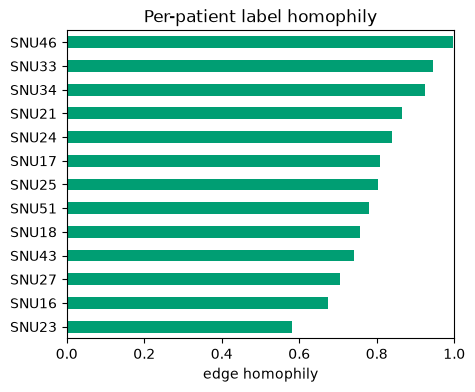

In [6]:
pd.Series(h["per_patient_edge_homophily"]).sort_values().plot.barh(figsize=(5, 4), color="#009E73")
plt.xlabel("edge homophily"); plt.title("Per-patient label homophily"); plt.xlim(0, 1); plt.show()

The labels are strongly homophilous: 0.80 overall, and above the shuffled-label chance level for every
class. In principle a spot's neighbours are informative about its label, so the graph had a fair chance.
That makes the null result a substantive finding rather than an artefact of a graph that carries no signal.

## 4. Patient splits

In [7]:
meta = pd.read_csv(PRE / "sections_meta.csv")
primary = json.load(open(REPO / "configs" / "splits.json"))
pd.DataFrame([{"set": k, "patients": ", ".join(primary[k]),
               "sections": int(meta.patient.isin(primary[k]).sum()),
               "labelled spots": int(meta[meta.patient.isin(primary[k])].n_labeled.sum())}
              for k in ("train", "val", "test")])

,set,patients,sections,labelled spots
0,train,"SNU17, SNU18, SNU21, SNU23, SNU25, SNU27, SNU4...",19,45924
1,val,"SNU24, SNU51",4,13396
2,test,"SNU16, SNU33, SNU34",5,16377


**Six repeated splits.** Split 0 is the primary split. The table below shows the labelled support of
each split's threshold-tuning block, the two validation patients
(`results/tables/supplement/TableS10_split_tuning_support.csv`).

In [8]:
s10 = pd.read_csv(RES / "tables" / "supplement" / "TableS10_split_tuning_support.csv")
s10[["split", "val_patients", "val_immune_cold", "val_immune_hot", "val_normal", "val_necrotic"]]

,split,val_patients,val_immune_cold,val_immune_hot,val_normal,val_necrotic
0,split0,SNU24 + SNU51,8638,15,2715,2028
1,split1,SNU18 + SNU25,3858,2997,4011,606
2,split2,SNU24 + SNU25,5647,7,5287,177
3,split3,SNU25 + SNU51,5003,10,4488,1879
4,split4,SNU25 + SNU46,1011,1,9685,19
5,split5,SNU17 + SNU18,2854,3705,481,3915


Four of the six tuning blocks hold fewer than 20 immune-hot spots, and split 4 holds one. The six-split
benchmark is therefore used **only** to measure how much results move with the choice of patients, not to
rank models.

**Leave-one-patient-out (primary analysis).** Each of the 13 folds holds out one patient. Two validation
patients are chosen from label counts alone, never from model performance.

In [9]:
folds = json.load(open(RES / "revision" / "folds.json"))
support = {}
for g in orig:
    y = g.niche_y.numpy(); s = support.setdefault(g.patient, np.zeros(4, int))
    s += np.array([(y == c).sum() for c in range(4)])
lopo = pd.DataFrame([{"test": k, "validation": " + ".join(v["val"]),
                      "min class support in validation": int(sum(support[p] for p in v["val"]).min())}
                     for k, v in folds.items()])
print("smallest per-class validation support over all folds:", lopo["min class support in validation"].min())
lopo

smallest per-class validation support over all folds: 183


,test,validation,min class support in validation
0,SNU16,SNU18 + SNU21,3141
1,SNU17,SNU23 + SNU27,1418
2,SNU18,SNU16 + SNU43,988
3,SNU21,SNU17 + SNU51,718
4,SNU23,SNU24 + SNU33,183
5,SNU24,SNU25 + SNU27,1204
6,SNU25,SNU18 + SNU46,597
7,SNU27,SNU21 + SNU34,381
8,SNU33,SNU16 + SNU43,988
9,SNU34,SNU17 + SNU23,924


Every LOPO tuning block holds at least 183 spots of every class, so thresholds are tuned on adequate
data in every fold. This is the main reason LOPO, not the six-split benchmark, carries the conclusion.